# myogen quickstart

From a hand movement to the forearm sEMG an armband would record: build a movement, simulate it, look at the EMG and at what the muscles did, save it.

Needs `pip install myogen[examples]` (matplotlib).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import myogen as mg

## 1. The movement

A `HandMotion` holds the 23 hand and wrist joint angles (radians) over time. `example_motion` is a few open-close grasps; for your own data use `mg.HandMotion.load(path, loader)`, with a loader that returns your file's angles in the model's joints (`mg.read_motion_file` reads myogen's own files), or a `mg.JointAdapter`.

In [2]:
motion = mg.example_motion(duration=4.0, fs=100)
print(motion.angles.shape, motion.fs, "Hz")
from myogen.simulation.musculoskeletal import HAND_JOINTS
print(HAND_JOINTS[:8])

(400, 23) 100.0 Hz
['pro_sup_r', 'deviation_r', 'flexion_r', 'cmc_flexion_r', 'cmc_abduction_r', 'mp_flexion_r', 'ip_flexion_r', 'mcp2_flexion_r']


## 2. Electrodes and simulation

`Electrodes.myo()` is the NinaPro DB5 setup: two Myo armbands, 16 channels, int8 counts at 200 Hz. `Simulator.run` goes movement → musculoskeletal model → muscle activity → EMG → device.

In [3]:
electrodes = mg.Electrodes.myo()
recording = mg.Simulator(electrodes).run(motion)
print(recording.emg.shape, recording.fs, "Hz")
print("QC pass:", recording.qc["pass"], f"(tracking RMSE {recording.qc['rmse_deg']:.2f} deg)")

Output()

(800, 16) 200.0 Hz
QC pass: True (tracking RMSE 0.68 deg)


## 3. The EMG and the labels

Besides the EMG, a `Recording` keeps what the hand and muscles did at 100 Hz: joint angles `q`, muscle `excitation` and `activation`, fibre lengths, effort, ...

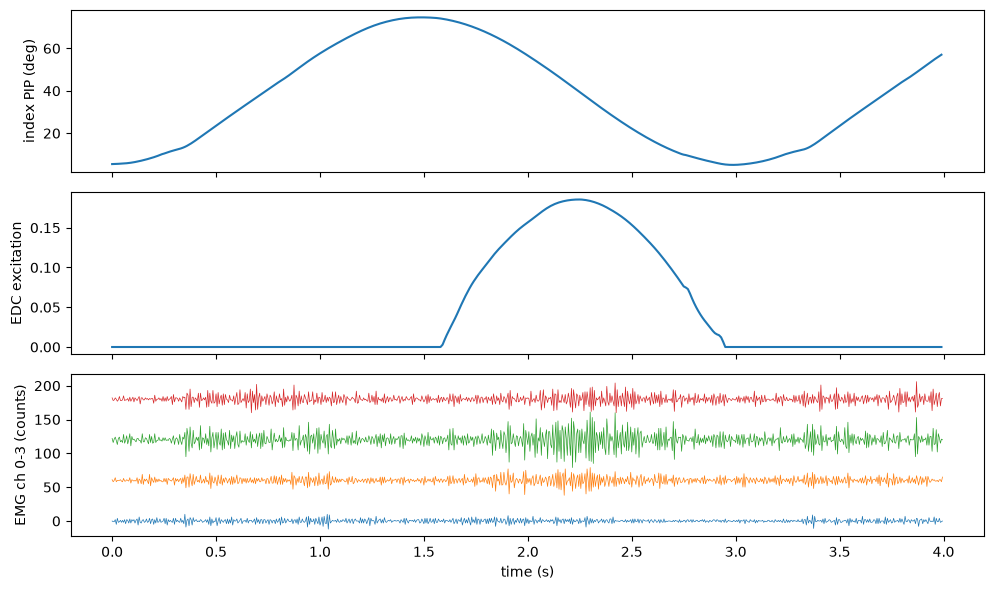

In [4]:
t_emg = np.arange(len(recording.emg)) / recording.fs
t_lab = np.arange(len(recording.labels["q"])) / recording.fs_labels
pip = recording.joint_names.index("pm2_flexion_r")
edc = recording.muscle_names.index("EDC3_r")

fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t_lab, np.degrees(recording.labels["q"][:, pip]))
ax[0].set_ylabel("index PIP (deg)")
ax[1].plot(t_lab, recording.labels["excitation"][:, edc])
ax[1].set_ylabel("EDC excitation")
ax[2].plot(t_emg, recording.emg[:, :4] + 60 * np.arange(4), lw=0.5)
ax[2].set_ylabel("EMG ch 0-3 (counts)")
ax[2].set_xlabel("time (s)")
plt.tight_layout()

## 4. Save, load and replay

Recordings are HDF5 files. To see the hand, the electrodes and the muscles move in 3-D, install `myogen[viewer]` and run `myogen replay quickstart.h5` (or `mg.replay(recording)`).

In [6]:
path = recording.save("quickstart.h5")
again = mg.Recording.load(path)
print(again.duration, "s,", len(again.electrodes), "channels,", list(again.labels))
mg.replay(recording)

4.0 s, 16 channels, ['activation', 'effort', 'excitation', 'fibre_length', 'grip_load', 'q', 'q_ref', 'qd', 'reserve']


╭────── viser (listening *:8080) ───────╮
│             ╷                         │
│   HTTP      │ http://localhost:8080   │
│   Websocket │ ws://localhost:8080     │
│             ╵                         │
╰───────────────────────────────────────╯

(viser) Server stopped